<a href="https://colab.research.google.com/github/ericrulz643/Insurance-Risk-Pricing-Analysis/blob/main/notebooks/insurance_risk_pricing_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [10]:
import pandas as pd

freq = pd.read_csv("freMTPL2freq.csv")
sev = pd.read_csv("freMTPL2sev.csv")

print("Frequency dataset:", freq.shape)
print("Severity dataset:", sev.shape)

display(freq.head())
display(sev.head())

Frequency dataset: (678013, 12)
Severity dataset: (26639, 2)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [ ]:
print("FREQUENCY DATA")
print("Shape:", freq.shape)
print("Columns:", freq.columns.tolist())
print()
print("Missing values:")
display(freq.isnull().sum())

print("\nSEVERITY DATA")
print("Shape:", sev.shape)
print("Columns:", sev.columns.tolist())
print()
print("Missing values:")
display(sev.isnull().sum())

In [ ]:
# Summary statistics for numerical variables
print("FREQUENCY DATA SUMMARY")
display(freq.describe().round(2))

print("SEVERITY DATA SUMMARY")
display(sev["ClaimAmount"].describe().round(2))

In [ ]:
total_claims = freq["ClaimNb"].sum()
total_exposure = freq["Exposure"].sum()
policies_with_claims = (freq["ClaimNb"] > 0).sum()

claim_frequency = total_claims / total_exposure

print(f"Number of policy records: {len(freq):,}")
print(f"Total claims recorded: {total_claims:,}")
print(f"Total exposure (policy-years): {total_exposure:,.2f}")
print(f"Policies with at least one claim: {policies_with_claims:,}")
print(f"Overall claim frequency: {claim_frequency:.4f} claims per policy-year")
print(f"Equivalent claims per 100 policy-years: {100 * claim_frequency:.2f}")

In [ ]:
# Group drivers into age bands
age_bins = [17, 25, 35, 45, 55, 65, 101]
age_labels = [
    "18–24", "25–34", "35–44",
    "45–54", "55–64", "65+"
]

freq["AgeGroup"] = pd.cut(
    freq["DrivAge"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Summarize claims and exposure by age group
age_analysis = (
    freq.groupby("AgeGroup", observed=False)
    .agg(
        Policies=("IDpol", "size"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

age_analysis["ClaimFrequency"] = (
    age_analysis["Claims"] / age_analysis["Exposure"]
)

age_analysis["ClaimsPer100PolicyYears"] = (
    100 * age_analysis["ClaimFrequency"]
)

display(age_analysis.round(4))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

age_analysis["ClaimsPer100PolicyYears"].plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Claim Frequency by Driver Age")
plt.xlabel("Driver Age Group")
plt.ylabel("Claims per 100 Policy-Years")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# Group vehicles by age
veh_age_bins = [-1, 1, 5, 10, 15, 20, float("inf")]
veh_age_labels = [
    "0–1", "2–5", "6–10", "11–15", "16–20", "21+"
]

freq["VehAgeGroup"] = pd.cut(
    freq["VehAge"],
    bins=veh_age_bins,
    labels=veh_age_labels
)

# Calculate claims and exposure by vehicle age
veh_age_analysis = (
    freq.groupby("VehAgeGroup", observed=False)
    .agg(
        Policies=("IDpol", "size"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

veh_age_analysis["ClaimsPer100PolicyYears"] = (
    100 * veh_age_analysis["Claims"] / veh_age_analysis["Exposure"]
)

display(veh_age_analysis.round(3))

In [ ]:
# Create population-density groups
freq["DensityGroup"] = pd.qcut(
    freq["Density"],
    q=5,
    duplicates="drop"
)

density_analysis = (
    freq.groupby("DensityGroup", observed=True)
    .agg(
        Policies=("IDpol", "size"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

density_analysis["ClaimsPer100PolicyYears"] = (
    100 * density_analysis["Claims"] / density_analysis["Exposure"]
)

display(density_analysis.round(3))

In [ ]:
print("Number of individual claims:", len(sev))
print("Total claim amount:", round(sev["ClaimAmount"].sum(), 2))
print("Average claim amount:", round(sev["ClaimAmount"].mean(), 2))
print("Median claim amount:", round(sev["ClaimAmount"].median(), 2))
print("Largest claim amount:", round(sev["ClaimAmount"].max(), 2))

display(sev["ClaimAmount"].describe().round(2))

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(sev["ClaimAmount"], bins=50, edgecolor="black")
plt.xscale("log")

plt.title("Distribution of Individual Claim Amounts")
plt.xlabel("Claim Amount (log scale)")
plt.ylabel("Number of Claims")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
upper_limit = sev["ClaimAmount"].quantile(0.99)

plt.figure(figsize=(9, 5))

plt.hist(
    sev.loc[sev["ClaimAmount"] <= upper_limit, "ClaimAmount"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Claim Amounts (Up to 99th Percentile)")
plt.xlabel("Claim Amount")
plt.ylabel("Number of Claims")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"99th percentile: {upper_limit:,.2f}")

In [ ]:
threshold = sev["ClaimAmount"].quantile(0.99)

largest_claims = sev[sev["ClaimAmount"] > threshold]

share_of_total = (
    largest_claims["ClaimAmount"].sum()
    / sev["ClaimAmount"].sum()
    * 100
)

print("Number of claims in the largest 1% group:", len(largest_claims))
print(f"Share of total claim amount: {share_of_total:.2f}%")

In [ ]:
# Overall claim frequency
total_claims = freq["ClaimNb"].sum()
total_exposure = freq["Exposure"].sum()
claim_frequency = total_claims / total_exposure

# Average claim severity
total_claim_cost = sev["ClaimAmount"].sum()
number_of_severity_records = len(sev)
average_severity = total_claim_cost / number_of_severity_records

# Initial pure premium estimate
pure_premium = claim_frequency * average_severity

print(f"Total claims in frequency data: {total_claims:,.0f}")
print(f"Total exposure: {total_exposure:,.2f} policy-years")
print(f"Claim frequency: {claim_frequency:.4f} claims per policy-year")
print(f"Average claim severity: {average_severity:,.2f}")
print(f"Estimated pure premium: {pure_premium:,.2f} per policy-year")

In [ ]:
print("Claims in frequency data:", freq["ClaimNb"].sum())
print("Severity records:", len(sev))
print("Total severity amount:", round(sev["ClaimAmount"].sum(), 2))
print("Unique policies in severity data:", sev["IDpol"].nunique())

In [ ]:
# Summarize claim counts by policy in the frequency data
print("Policies with at least one claim:",
      (freq["ClaimNb"] > 0).sum())

print("Policies with multiple claims:",
      (freq["ClaimNb"] > 1).sum())

print("Total claims from policies with multiple claims:",
      freq.loc[freq["ClaimNb"] > 1, "ClaimNb"].sum())

# Check the distribution of severity records per policy
severity_records_per_policy = sev.groupby("IDpol").size()

print("\nPolicies with multiple severity records:",
      (severity_records_per_policy > 1).sum())

print("Maximum severity records for one policy:",
      severity_records_per_policy.max())

In [ ]:
# Compare policy IDs across the two datasets
freq_policy_ids = set(freq["IDpol"])
sev_policy_ids = set(sev["IDpol"])

print("Unique policies in frequency data:", len(freq_policy_ids))
print("Unique policies in severity data:", len(sev_policy_ids))

print("Severity policies also found in frequency data:",
      len(sev_policy_ids & freq_policy_ids))

# Check whether severity policies have claims in the frequency data
freq_claims_by_policy = freq.set_index("IDpol")["ClaimNb"]

severity_policy_claims = freq_claims_by_policy.reindex(sev["IDpol"].unique())

print("Severity policies with no claims in frequency data:",
      (severity_policy_claims == 0).sum())

print("Severity policies with at least one claim:",
      (severity_policy_claims > 0).sum())

In [ ]:
# Total number of claims reported by policies present in both files
matched_policy_ids = sev["IDpol"].unique()
matched_claim_counts = (
    freq.loc[freq["IDpol"].isin(matched_policy_ids), "ClaimNb"].sum()
)

print("Severity records:", len(sev))
print("Claims reported by matched policies:", matched_claim_counts)
print("Difference:", matched_claim_counts - len(sev))

# Compare the number of claims and severity records by policy
severity_counts = sev.groupby("IDpol").size().rename("SeverityRecords")

policy_comparison = (
    freq.set_index("IDpol")[["ClaimNb"]]
    .join(severity_counts, how="inner")
)

print("\nPolicies where claim count differs from severity-record count:",
      (policy_comparison["ClaimNb"] != policy_comparison["SeverityRecords"]).sum())

print("\nFirst few mismatches:")
print(
    policy_comparison.loc[
        policy_comparison["ClaimNb"] != policy_comparison["SeverityRecords"]
    ].head(10)
)

In [ ]:
# Compare totals using the same joined table
print("Frequency claim total for matched policies:",
      policy_comparison["ClaimNb"].sum())

print("Severity record total for matched policies:",
      policy_comparison["SeverityRecords"].sum())

print("Number of policies compared:",
      len(policy_comparison))

print("Missing claim counts:",
      policy_comparison["ClaimNb"].isna().sum())

print("Missing severity counts:",
      policy_comparison["SeverityRecords"].isna().sum())

# Show all policies with unequal counts, including missing values
mismatches = policy_comparison[
    policy_comparison["ClaimNb"].ne(policy_comparison["SeverityRecords"])
]

print("\nNumber of mismatches:", len(mismatches))
print(mismatches.head(20))

In [ ]:
# Severity policy IDs not found in the frequency data
unmatched_ids = sev.loc[
    ~sev["IDpol"].isin(freq["IDpol"]), "IDpol"
].unique()

print("Unmatched severity policy IDs:", unmatched_ids)

print("\nSeverity records for unmatched policies:")
print(
    sev[sev["IDpol"].isin(unmatched_ids)]
    .sort_values("IDpol")
)

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Keep policies with positive exposure
model_data = freq.loc[freq["Exposure"] > 0].copy()

# Create age groups
model_data["DriverAgeGroup"] = pd.cut(
    model_data["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, float("inf")],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
    right=False
)

# Create vehicle age groups
model_data["VehicleAgeGroup"] = pd.cut(
    model_data["VehAge"],
    bins=[-1, 1, 5, 10, 15, 20, float("inf")],
    labels=["0-1", "2-5", "6-10", "11-15", "16-20", "21+"]
)

# Use log population density to reduce its extreme right skew
model_data["LogDensity"] = np.log1p(model_data["Density"])

print("Original policy records:", len(freq))
print("Records used in model:", len(model_data))
print("Total claims in model:", model_data["ClaimNb"].sum())
print("Total exposure in model:", round(model_data["Exposure"].sum(), 2))
print("Missing values in modeling variables:")
print(model_data[
    ["ClaimNb", "Exposure", "DriverAgeGroup", "VehicleAgeGroup", "LogDensity"]
].isna().sum())

In [ ]:
# Fit a Poisson regression with an exposure offset
poisson_model = smf.glm(
    formula=(
        "ClaimNb ~ C(DriverAgeGroup) "
        "+ C(VehicleAgeGroup) "
        "+ LogDensity"
    ),
    data=model_data,
    family=sm.families.Poisson(),
    offset=np.log(model_data["Exposure"])
).fit()

print(poisson_model.summary())

In [ ]:
# Convert model coefficients to rate ratios
rate_ratios = np.exp(poisson_model.params)

results = pd.DataFrame({
    "Coefficient": poisson_model.params,
    "Rate Ratio": rate_ratios,
    "Percent Change": (rate_ratios - 1) * 100,
    "P-value": poisson_model.pvalues
})

print(results.round(4))

# Check for overdispersion
pearson_dispersion = (
    poisson_model.pearson_chi2 / poisson_model.df_resid
)

print(f"\nPearson dispersion ratio: {pearson_dispersion:.3f}")

In [ ]:
negative_binomial_model = smf.glm(
    formula=(
        "ClaimNb ~ C(DriverAgeGroup) "
        "+ C(VehicleAgeGroup) "
        "+ LogDensity"
    ),
    data=model_data,
    family=sm.families.NegativeBinomial(alpha=1.0),
    offset=np.log(model_data["Exposure"])
).fit()

print(negative_binomial_model.summary())

In [ ]:
from statsmodels.discrete.discrete_model import NegativeBinomial

nb_model = NegativeBinomial.from_formula(
    "ClaimNb ~ C(DriverAgeGroup) + C(VehicleAgeGroup) + LogDensity",
    data=model_data,
    exposure=model_data["Exposure"]
)

nb_results = nb_model.fit(maxiter=100, disp=False)

print(nb_results.summary())

In [ ]:
poisson_robust = smf.glm(
    formula=(
        "ClaimNb ~ C(DriverAgeGroup) "
        "+ C(VehicleAgeGroup) "
        "+ LogDensity"
    ),
    data=model_data,
    family=sm.families.Poisson(),
    offset=np.log(model_data["Exposure"])
).fit(cov_type="HC0")

print(poisson_robust.summary())

In [ ]:
import numpy as np
import pandas as pd

params = poisson_robust.params
conf = poisson_robust.conf_int()

results_table = pd.DataFrame({
    "Coefficient": params,
    "Rate Ratio": np.exp(params),
    "RR 95% CI Lower": np.exp(conf[0]),
    "RR 95% CI Upper": np.exp(conf[1]),
    "P-value": poisson_robust.pvalues
})

results_table = results_table.drop("Intercept")

results_table = results_table.round({
    "Coefficient": 4,
    "Rate Ratio": 3,
    "RR 95% CI Lower": 3,
    "RR 95% CI Upper": 3,
    "P-value": 4
})

results_table

In [ ]:
# Calculate predicted claim counts for each policy
model_data["PredictedClaims"] = poisson_robust.predict(
    model_data,
    offset=np.log(model_data["Exposure"])
)

# Rank policies into 10 groups based on predicted claim rate
model_data["RiskDecile"] = pd.qcut(
    model_data["PredictedClaims"] / model_data["Exposure"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

# Compare actual and predicted frequency by risk decile
validation_table = (
    model_data.groupby("RiskDecile", observed=True)
    .agg(
        Policies=("ClaimNb", "size"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum"),
        Exposure=("Exposure", "sum")
    )
    .reset_index()
)

validation_table["ActualFrequency"] = (
    validation_table["ActualClaims"] / validation_table["Exposure"]
)

validation_table["PredictedFrequency"] = (
    validation_table["PredictedClaims"] / validation_table["Exposure"]
)

validation_table["ActualClaimsPer100Years"] = (
    100 * validation_table["ActualFrequency"]
)

validation_table["PredictedClaimsPer100Years"] = (
    100 * validation_table["PredictedFrequency"]
)

validation_table.round(3)

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    validation_table["RiskDecile"],
    validation_table["ActualClaimsPer100Years"],
    marker="o",
    label="Actual frequency"
)

plt.plot(
    validation_table["RiskDecile"],
    validation_table["PredictedClaimsPer100Years"],
    marker="s",
    linestyle="--",
    label="Predicted frequency"
)

plt.xlabel("Predicted Risk Decile (1 = Lowest Risk)")
plt.ylabel("Claims per 100 Policy-Years")
plt.title("Actual vs. Predicted Claim Frequency by Risk Decile")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("Number of records:", len(model_data))
print("Number of folds:", kf.get_n_splits())

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_poisson_deviance

formula = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity"
)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    # Fit model using training data only
    model = smf.glm(
        formula=formula,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    # Predict claim counts for held-out policies
    predicted = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    # Calculate out-of-sample performance
    deviance = mean_poisson_deviance(
        test["ClaimNb"],
        predicted / test["Exposure"]
    )

    actual_frequency = (
        test["ClaimNb"].sum() / test["Exposure"].sum()
    )

    predicted_frequency = (
        predicted.sum() / test["Exposure"].sum()
    )

    cv_results.append({
        "Fold": fold,
        "TestRecords": len(test),
        "ActualFrequency": actual_frequency,
        "PredictedFrequency": predicted_frequency,
        "MeanPoissonDeviance": deviance
    })

cv_table = pd.DataFrame(cv_results)
cv_table.round(5)

In [ ]:
from sklearn.metrics import mean_poisson_deviance

cv_deviance = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    model = smf.glm(
        formula=formula,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    predicted = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    deviance = mean_poisson_deviance(
        test["ClaimNb"],
        predicted
    )

    cv_deviance.append({
        "Fold": fold,
        "MeanPoissonDeviance": deviance
    })

cv_deviance = pd.DataFrame(cv_deviance)

print(cv_deviance.round(5))
print(
    "\nAverage cross-validation deviance:",
    round(cv_deviance["MeanPoissonDeviance"].mean(), 5)
)
print(
    "Standard deviation across folds:",
    round(cv_deviance["MeanPoissonDeviance"].std(), 5)
)

In [ ]:
from sklearn.metrics import mean_poisson_deviance

baseline_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    # Estimate one overall claim rate from training data
    overall_rate = train["ClaimNb"].sum() / train["Exposure"].sum()

    # Predict each test policy's claim count using its exposure
    baseline_pred = overall_rate * test["Exposure"]

    # Fit the risk-factor model using training data only
    model = smf.glm(
        formula=formula,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    model_pred = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    baseline_deviance = mean_poisson_deviance(
        test["ClaimNb"], baseline_pred
    )

    model_deviance = mean_poisson_deviance(
        test["ClaimNb"], model_pred
    )

    baseline_results.append({
        "Fold": fold,
        "BaselineDeviance": baseline_deviance,
        "GLMDeviance": model_deviance
    })

baseline_table = pd.DataFrame(baseline_results)

baseline_table["ImprovementPercent"] = (
    100 * (
        baseline_table["BaselineDeviance"]
        - baseline_table["GLMDeviance"]
    ) / baseline_table["BaselineDeviance"]
)

print(baseline_table.round(5))

print("\nAverage baseline deviance:",
      round(baseline_table["BaselineDeviance"].mean(), 5))

print("Average GLM deviance:",
      round(baseline_table["GLMDeviance"].mean(), 5))

print("Average deviance improvement (%):",
      round(baseline_table["ImprovementPercent"].mean(), 2))

In [ ]:
# Fit a Negative Binomial GLM
negative_binomial_model = smf.glm(
    formula=formula,
    data=model_data,
    family=sm.families.NegativeBinomial(alpha=0.5),
    offset=np.log(model_data["Exposure"])
).fit()

print(negative_binomial_model.summary())

In [ ]:
from sklearn.metrics import mean_poisson_deviance

alpha_values = [0.1, 0.5, 1.0]
nb_cv_results = []

for alpha in alpha_values:
    fold_scores = []

    for fold, (train_idx, test_idx) in enumerate(
        kf.split(model_data), start=1
    ):
        train = model_data.iloc[train_idx]
        test = model_data.iloc[test_idx]

        nb_model = smf.glm(
            formula=formula,
            data=train,
            family=sm.families.NegativeBinomial(alpha=alpha),
            offset=np.log(train["Exposure"])
        ).fit()

        predicted = nb_model.predict(
            test,
            offset=np.log(test["Exposure"])
        )

        deviance = mean_poisson_deviance(
            test["ClaimNb"], predicted
        )

        fold_scores.append(deviance)

    nb_cv_results.append({
        "Alpha": alpha,
        "Average CV Deviance": np.mean(fold_scores),
        "CV Standard Deviation": np.std(fold_scores, ddof=1)
    })

nb_cv_results = pd.DataFrame(nb_cv_results)
print(nb_cv_results.round(5).to_string(index=False))

In [ ]:
expanded_formula = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity "
    "+ BonusMalus"
)

expanded_cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    model = smf.glm(
        formula=expanded_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    predicted = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    deviance = mean_poisson_deviance(
        test["ClaimNb"], predicted
    )

    expanded_cv_results.append(deviance)

print("Expanded model average CV deviance:",
      round(np.mean(expanded_cv_results), 5))
print("Expanded model CV standard deviation:",
      round(np.std(expanded_cv_results, ddof=1), 5))
print("Previous model average CV deviance: 0.32535")

In [ ]:
expanded_formula_2 = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity "
    "+ BonusMalus "
    "+ C(VehPower)"
)

vehpower_cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    model = smf.glm(
        formula=expanded_formula_2,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    predicted = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    deviance = mean_poisson_deviance(
        test["ClaimNb"], predicted
    )

    vehpower_cv_results.append(deviance)

print("Model with BonusMalus and VehPower:")
print("Average CV deviance:",
      round(np.mean(vehpower_cv_results), 5))
print("CV standard deviation:",
      round(np.std(vehpower_cv_results, ddof=1), 5))
print("Previous model average CV deviance: 0.31958")

In [ ]:
expanded_formula_3 = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity "
    "+ BonusMalus "
    "+ C(VehPower) "
    "+ C(VehBrand)"
)

brand_cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    model = smf.glm(
        formula=expanded_formula_3,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    predicted = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    deviance = mean_poisson_deviance(
        test["ClaimNb"], predicted
    )

    brand_cv_results.append(deviance)

print("Model with BonusMalus, VehPower, and VehBrand:")
print("Average CV deviance:",
      round(np.mean(brand_cv_results), 5))
print("CV standard deviation:",
      round(np.std(brand_cv_results, ddof=1), 5))
print("Previous model average CV deviance: 0.31922")

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_poisson_deviance

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("Cross-validation setup restored.")

In [ ]:
print("model_data:", model_data.shape)
print("Exposure available:", "Exposure" in model_data.columns)
print("VehBrand available:", "VehBrand" in model_data.columns)

In [ ]:
expanded_formula_4 = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity "
    "+ BonusMalus "
    "+ C(VehPower) "
    "+ C(VehBrand) "
    "+ C(Area)"
)

area_cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(model_data), start=1
):
    train = model_data.iloc[train_idx]
    test = model_data.iloc[test_idx]

    model = smf.glm(
        formula=expanded_formula_4,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    predicted = model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

    deviance = mean_poisson_deviance(
        test["ClaimNb"], predicted
    )

    area_cv_results.append(deviance)

print("Model including Area:")
print("Average CV deviance:",
      round(np.mean(area_cv_results), 5))
print("CV standard deviation:",
      round(np.std(area_cv_results, ddof=1), 5))
print("Previous model average CV deviance: 0.31910")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import KFold
from sklearn.metrics import mean_poisson_deviance

freq = pd.read_csv("/content/freMTPL2freq.csv")
sev = pd.read_csv("/content/freMTPL2sev.csv")

In [41]:
model_data = freq.loc[freq["Exposure"] > 0].copy()

model_data["DriverAgeGroup"] = pd.cut(
    model_data["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, float("inf")],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
    right=False
)

model_data["VehicleAgeGroup"] = pd.cut(
    model_data["VehAge"],
    bins=[-1, 1, 5, 10, 15, 20, float("inf")],
    labels=["0-1", "2-5", "6-10", "11-15", "16-20", "21+"]
)

model_data["LogDensity"] = np.log1p(model_data["Density"])

print("Model data restored:", model_data.shape)

Model data restored: (678013, 15)


In [42]:
model_sample = model_data.sample(
    n=150_000,
    random_state=42
).copy()

kf_sample = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Sample size:", len(model_sample))

Sample size: 150000


In [43]:
model_sample = model_data.sample(
    n=150_000,
    random_state=42
).copy()

kf_sample = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Sample size:", len(model_sample))

Sample size: 150000


In [44]:
base_formula = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity "
    "+ BonusMalus "
    "+ C(VehPower) "
    "+ C(VehBrand)"
)

area_formula = base_formula + " + C(Area)"

comparison_results = []

for name, formula_test in [
    ("Without Area", base_formula),
    ("With Area", area_formula)
]:
    fold_scores = []

    for train_idx, test_idx in kf_sample.split(model_sample):
        train = model_sample.iloc[train_idx]
        test = model_sample.iloc[test_idx]

        fitted_model = smf.glm(
            formula=formula_test,
            data=train,
            family=sm.families.Poisson(),
            offset=np.log(train["Exposure"])
        ).fit()

        predictions = fitted_model.predict(
            test,
            offset=np.log(test["Exposure"])
        )

        fold_scores.append(
            mean_poisson_deviance(
                test["ClaimNb"], predictions
            )
        )

    comparison_results.append({
        "Model": name,
        "Average CV Deviance": np.mean(fold_scores),
        "CV Standard Deviation": np.std(fold_scores, ddof=1)
    })

print(pd.DataFrame(comparison_results).round(5).to_string(index=False))

       Model  Average CV Deviance  CV Standard Deviation
Without Area              0.32057                0.00567
   With Area              0.32061                0.00572


In [ ]:
region_formula = base_formula + " + C(Region)"

region_comparison = []

for name, formula_test in [
    ("Without Region", base_formula),
    ("With Region", region_formula)
]:
    fold_scores = []

    for train_idx, test_idx in kf_sample.split(model_sample):
        train = model_sample.iloc[train_idx]
        test = model_sample.iloc[test_idx]

        fitted_model = smf.glm(
            formula=formula_test,
            data=train,
            family=sm.families.Poisson(),
            offset=np.log(train["Exposure"])
        ).fit()

        predictions = fitted_model.predict(
            test,
            offset=np.log(test["Exposure"])
        )

        fold_scores.append(
            mean_poisson_deviance(
                test["ClaimNb"], predictions
            )
        )

    region_comparison.append({
        "Model": name,
        "Average CV Deviance": np.mean(fold_scores),
        "CV Standard Deviation": np.std(fold_scores, ddof=1)
    })

print(pd.DataFrame(region_comparison).round(5).to_string(index=False))

In [ ]:
gas_formula = base_formula + " + C(VehGas)"

gas_comparison = []

for name, formula_test in [
    ("Without VehGas", base_formula),
    ("With VehGas", gas_formula)
]:
    fold_scores = []

    for train_idx, test_idx in kf_sample.split(model_sample):
        train = model_sample.iloc[train_idx]
        test = model_sample.iloc[test_idx]

        fitted_model = smf.glm(
            formula=formula_test,
            data=train,
            family=sm.families.Poisson(),
            offset=np.log(train["Exposure"])
        ).fit()

        predictions = fitted_model.predict(
            test,
            offset=np.log(test["Exposure"])
        )

        fold_scores.append(
            mean_poisson_deviance(
                test["ClaimNb"], predictions
            )
        )

    gas_comparison.append({
        "Model": name,
        "Average CV Deviance": np.mean(fold_scores),
        "CV Standard Deviation": np.std(fold_scores, ddof=1)
    })

print(pd.DataFrame(gas_comparison).round(5).to_string(index=False))

In [ ]:
final_formula = (
    "ClaimNb ~ C(DriverAgeGroup) "
    "+ C(VehicleAgeGroup) "
    "+ LogDensity "
    "+ BonusMalus "
    "+ C(VehPower) "
    "+ C(VehBrand) "
    "+ C(VehGas)"
)

final_model = smf.glm(
    formula=final_formula,
    data=model_sample,
    family=sm.families.Poisson(),
    offset=np.log(model_sample["Exposure"])
).fit(cov_type="HC0")

print(final_model.summary())

In [ ]:
# Convert coefficients and confidence intervals to rate ratios
coef = final_model.params
ci = final_model.conf_int()

rate_ratio_table = pd.DataFrame({
    "Coefficient": coef,
    "Rate Ratio": np.exp(coef),
    "95% CI Lower": np.exp(ci[0]),
    "95% CI Upper": np.exp(ci[1]),
    "P-value": final_model.pvalues
})

# Exclude the intercept and format the results
rate_ratio_table = rate_ratio_table.drop("Intercept")
rate_ratio_table["P-value"] = rate_ratio_table["P-value"].map(
    lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
)

print(rate_ratio_table.round(3).to_string())

In [18]:
from sklearn.model_selection import KFold

oof_predictions = np.zeros(len(model_sample))

for train_idx, test_idx in kf_sample.split(model_sample):
    train = model_sample.iloc[train_idx]
    test = model_sample.iloc[test_idx]

    fold_model = smf.glm(
        formula=final_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    oof_predictions[test_idx] = fold_model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

print("Policies evaluated:", len(oof_predictions))
print("Predictions generated:", np.isfinite(oof_predictions).sum())
print("Average predicted claims per policy:", oof_predictions.mean())

NameError: name 'model_sample' is not defined

In [ ]:
# Create a validation table using out-of-fold predictions
validation_data = model_sample[
    ["ClaimNb", "Exposure"]
].copy()

validation_data["PredictedClaims"] = oof_predictions

validation_data["RiskDecile"] = pd.qcut(
    validation_data["PredictedClaims"].rank(method="first"),
    q=10,
    labels=False
) + 1

decile_validation = (
    validation_data
    .groupby("RiskDecile", observed=True)
    .agg(
        Policies=("ClaimNb", "size"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum"),
        Exposure=("Exposure", "sum")
    )
    .reset_index()
)

decile_validation["ActualFreqPer100"] = (
    100 * decile_validation["ActualClaims"]
    / decile_validation["Exposure"]
)

decile_validation["PredictedFreqPer100"] = (
    100 * decile_validation["PredictedClaims"]
    / decile_validation["Exposure"]
)

print(decile_validation.round(3).to_string(index=False))

In [ ]:
validation_data = model_sample[
    ["ClaimNb", "Exposure"]
].copy()

validation_data["PredictedClaims"] = oof_predictions

# Estimate claim frequency per policy-year
validation_data["PredictedRate"] = (
    validation_data["PredictedClaims"]
    / validation_data["Exposure"]
)

# Rank policies by predicted frequency, not predicted claim count
validation_data["RiskDecile"] = pd.qcut(
    validation_data["PredictedRate"].rank(method="first"),
    q=10,
    labels=False
) + 1

decile_validation = (
    validation_data
    .groupby("RiskDecile", observed=True)
    .agg(
        Policies=("ClaimNb", "size"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum"),
        Exposure=("Exposure", "sum")
    )
    .reset_index()
)

decile_validation["ActualFreqPer100"] = (
    100 * decile_validation["ActualClaims"]
    / decile_validation["Exposure"]
)

decile_validation["PredictedFreqPer100"] = (
    100 * decile_validation["PredictedClaims"]
    / decile_validation["Exposure"]
)

print(decile_validation.round(3).to_string(index=False))

In [13]:
from sklearn.model_selection import KFold

oof_predictions = np.zeros(len(model_sample))

for train_idx, test_idx in kf_sample.split(model_sample):
    train = model_sample.iloc[train_idx]
    test = model_sample.iloc[test_idx]

    fold_model = smf.glm(
        formula=final_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    ).fit()

    oof_predictions[test_idx] = fold_model.predict(
        test,
        offset=np.log(test["Exposure"])
    )

print("Policies evaluated:", len(oof_predictions))
print("Predictions generated:", np.isfinite(oof_predictions).sum())
print("Average predicted claims per policy:", oof_predictions.mean())

NameError: name 'model_sample' is not defined

In [22]:
actual_total = model_sample["ClaimNb"].sum()
predicted_total = oof_predictions.sum()

print(f"Actual claims: {actual_total:.2f}")
print(f"Predicted claims: {predicted_total:.2f}")
print(
    "Relative prediction error: "
    f"{100 * (predicted_total - actual_total) / actual_total:.2f}%"
)

Actual claims: 8037.00
Predicted claims: 8038.49
Relative prediction error: 0.02%


In [23]:
print("Severity dataset shape:", sev.shape)
print("\nColumn names:")
print(sev.columns.tolist())

print("\nFirst five rows:")
display(sev.head())

print("\nSummary statistics:")
display(sev["ClaimAmount"].describe())

print("\nMissing values:")
print(sev.isnull().sum())

Severity dataset shape: (26639, 2)

Column names:
['IDpol', 'ClaimAmount']

First five rows:


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00



Summary statistics:


,ClaimAmount
count,2.663900e+04
mean,2.278536e+03
std,2.929748e+04
min,1.000000e+00
25%,6.868100e+02
50%,1.172000e+03
75%,1.228080e+03
max,4.075401e+06



Missing values:
IDpol          0
ClaimAmount    0
dtype: int64


In [24]:
total_claim_amount = sev["ClaimAmount"].sum()

percentiles = sev["ClaimAmount"].quantile(
    [0.90, 0.95, 0.99, 0.995]
)

print(f"Number of claims: {len(sev):,}")
print(f"Total claim amount: {total_claim_amount:,.2f}")
print(f"Mean claim amount: {sev['ClaimAmount'].mean():,.2f}")
print(f"Median claim amount: {sev['ClaimAmount'].median():,.2f}")

print("\nClaim amount percentiles:")
print(percentiles.round(2).to_string())

print("\nContribution of largest claims:")
for percentile in [0.90, 0.95, 0.99, 0.995]:
    threshold = sev["ClaimAmount"].quantile(percentile)
    largest_claims = sev.loc[
        sev["ClaimAmount"] >= threshold, "ClaimAmount"
    ]

    share = 100 * largest_claims.sum() / total_claim_amount

    print(
        f"Top {100 * (1 - percentile):.1f}% of claims: "
        f"{len(largest_claims):,} claims, "
        f"{share:.2f}% of total claim amount"
    )

Number of claims: 26,639
Total claim amount: 60,697,930.68
Mean claim amount: 2,278.54
Median claim amount: 1,172.00

Claim amount percentiles:
0.900     2799.07
0.950     4861.68
0.990    16793.70
0.995    34386.99

Contribution of largest claims:
Top 10.0% of claims: 2,664 claims, 60.01% of total claim amount
Top 5.0% of claims: 1,332 claims, 52.11% of total claim amount
Top 1.0% of claims: 267 claims, 37.96% of total claim amount
Top 0.5% of claims: 134 claims, 32.90% of total claim amount


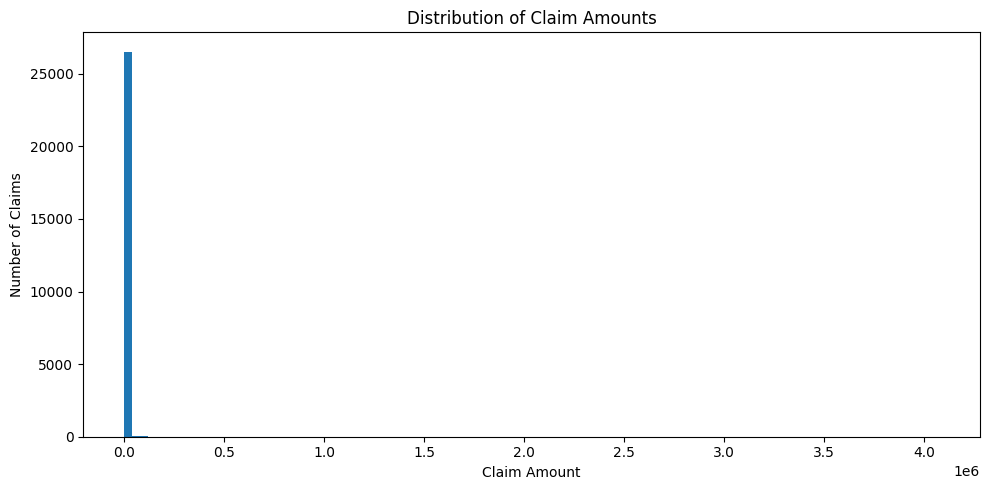

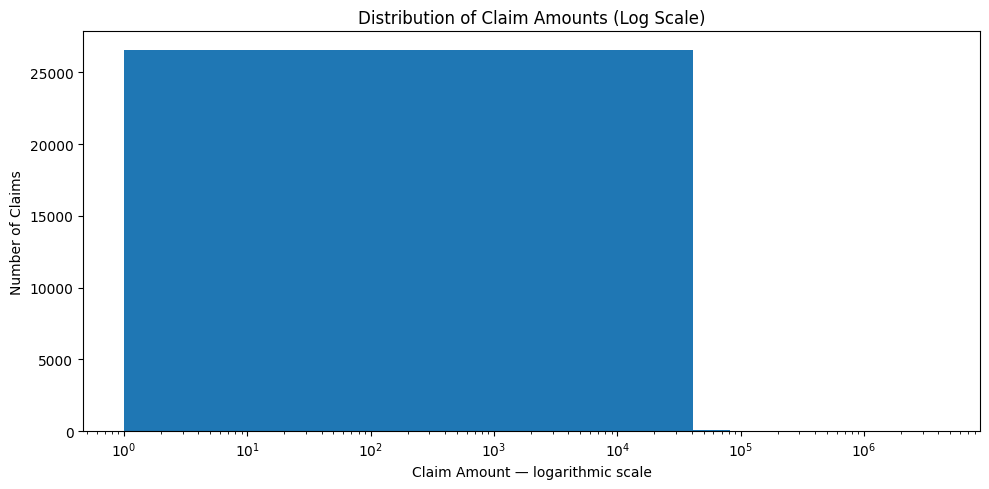

In [25]:
import matplotlib.pyplot as plt

# Original scale
plt.figure(figsize=(10, 5))
plt.hist(sev["ClaimAmount"], bins=100)
plt.title("Distribution of Claim Amounts")
plt.xlabel("Claim Amount")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

# Logarithmic scale
plt.figure(figsize=(10, 5))
plt.hist(sev["ClaimAmount"], bins=100)
plt.xscale("log")
plt.title("Distribution of Claim Amounts (Log Scale)")
plt.xlabel("Claim Amount — logarithmic scale")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

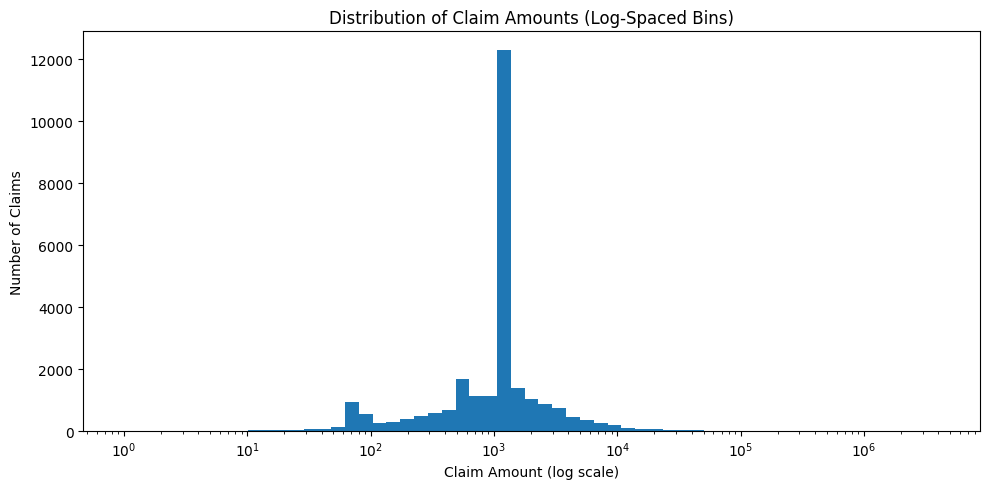

In [26]:
import numpy as np
import matplotlib.pyplot as plt

claim_amounts = sev["ClaimAmount"]

# Create bin edges evenly spaced on a logarithmic scale
log_bins = np.logspace(
    np.log10(claim_amounts.min()),
    np.log10(claim_amounts.max()),
    60
)

plt.figure(figsize=(10, 5))
plt.hist(claim_amounts, bins=log_bins)
plt.xscale("log")
plt.title("Distribution of Claim Amounts (Log-Spaced Bins)")
plt.xlabel("Claim Amount (log scale)")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

In [27]:
import statsmodels.api as sm
import numpy as np

severity_model = sm.GLM(
    sev["ClaimAmount"],
    np.ones((len(sev), 1)),
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

print(severity_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            ClaimAmount   No. Observations:                26639
Model:                            GLM   Df Residuals:                    26638
Model Family:                   Gamma   Df Model:                            0
Link Function:                    Log   Scale:                          165.33
Method:                          IRLS   Log-Likelihood:            -3.1958e+05
Date:                Mon, 26 Oct 2026   Deviance:                       46962.
Time:                        21:27:45   Pearson chi2:                 4.40e+06
No. Iterations:                     8   Pseudo R-squ. (CS):              0.000
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.7313      0.079     98.138      0.0

In [28]:
claim_amounts = sev["ClaimAmount"]

threshold_99 = claim_amounts.quantile(0.99)

trimmed_claims = claim_amounts[
    claim_amounts <= threshold_99
]

print(f"99th percentile threshold: {threshold_99:,.2f}")
print(f"Original mean: {claim_amounts.mean():,.2f}")
print(f"Mean excluding claims above the 99th percentile: "
      f"{trimmed_claims.mean():,.2f}")
print(f"Original median: {claim_amounts.median():,.2f}")
print(f"Number of claims excluded: "
      f"{len(claim_amounts) - len(trimmed_claims):,}")

99th percentile threshold: 16,793.70
Original mean: 2,278.54
Mean excluding claims above the 99th percentile: 1,428.01
Original median: 1,172.00
Number of claims excluded: 267


In [29]:
import numpy as np
from scipy import stats

log_claims = np.log(sev["ClaimAmount"])

# Fit a normal distribution to log claim amounts
log_mean = log_claims.mean()
log_std = log_claims.std(ddof=1)

# Convert lognormal parameters back to the claim-amount scale
lognormal_median = np.exp(log_mean)
lognormal_mean = np.exp(log_mean + 0.5 * log_std**2)

print(f"Mean of log claim amounts: {log_mean:.4f}")
print(f"Standard deviation of log claim amounts: {log_std:.4f}")
print(f"Implied lognormal median: {lognormal_median:,.2f}")
print(f"Implied lognormal mean: {lognormal_mean:,.2f}")
print(f"Observed median: {sev['ClaimAmount'].median():,.2f}")
print(f"Observed mean: {sev['ClaimAmount'].mean():,.2f}")

Mean of log claim amounts: 6.8498
Standard deviation of log claim amounts: 1.1327
Implied lognormal median: 943.73
Implied lognormal mean: 1,792.40
Observed median: 1,172.00
Observed mean: 2,278.54


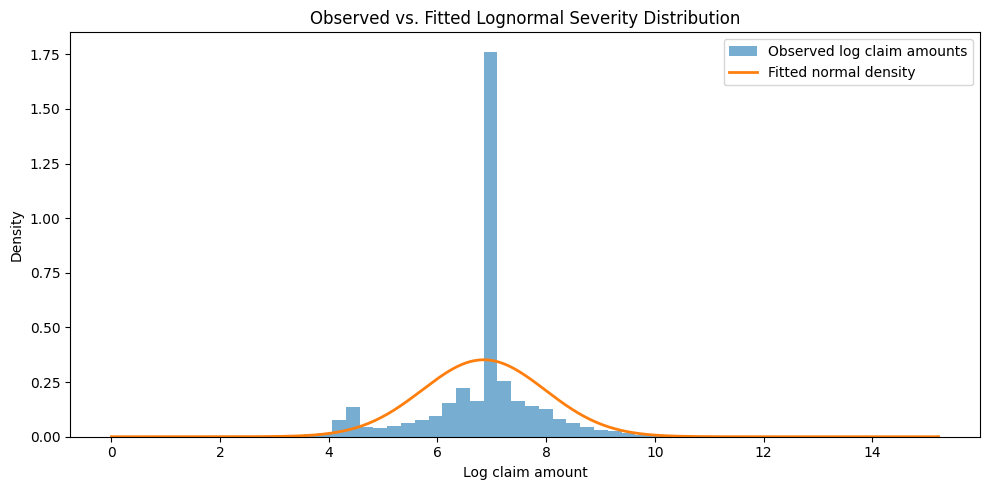

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

log_claims = np.log(sev["ClaimAmount"])

plt.figure(figsize=(10, 5))

plt.hist(
    log_claims,
    bins=60,
    density=True,
    alpha=0.6,
    label="Observed log claim amounts"
)

x = np.linspace(log_claims.min(), log_claims.max(), 400)

plt.plot(
    x,
    norm.pdf(x, loc=log_mean, scale=log_std),
    linewidth=2,
    label="Fitted normal density"
)

plt.title("Observed vs. Fitted Lognormal Severity Distribution")
plt.xlabel("Log claim amount")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
from scipy.stats import lognorm

# Fit a lognormal distribution to the claim amounts
shape, loc, scale = lognorm.fit(sev["ClaimAmount"], floc=0)

percentiles = [50, 75, 90, 95, 99, 99.5, 99.9]

comparison = pd.DataFrame({
    "Percentile": percentiles,
    "Observed": np.percentile(sev["ClaimAmount"], percentiles),
    "Fitted Lognormal": lognorm.ppf(
        np.array(percentiles) / 100,
        shape,
        loc=loc,
        scale=scale
    )
})

comparison["Difference (%)"] = (
    100 * (
        comparison["Fitted Lognormal"] - comparison["Observed"]
    ) / comparison["Observed"]
)

comparison.round(2)

,Percentile,Observed,Fitted Lognormal,Difference (%)
0,50.0,1172.00,943.73,-19.48
1,75.0,1228.08,2025.96,64.97
2,90.0,2799.07,4029.47,43.96
3,95.0,4861.68,6080.76,25.08
4,99.0,16793.70,13157.95,-21.65
5,99.5,34386.99,17454.57,-49.24
6,99.9,162784.44,31256.94,-80.80


In [32]:
from scipy.stats import gamma, lognorm
import numpy as np
import pandas as pd

claims = sev["ClaimAmount"].to_numpy()

# Fit Gamma distribution
gamma_shape, gamma_loc, gamma_scale = gamma.fit(claims, floc=0)

# Fit lognormal distribution
lognorm_shape, lognorm_loc, lognorm_scale = lognorm.fit(
    claims, floc=0
)

percentiles = np.array([50, 75, 90, 95, 99, 99.5, 99.9])
probabilities = percentiles / 100

comparison = pd.DataFrame({
    "Percentile": percentiles,
    "Observed": np.percentile(claims, percentiles),
    "Gamma": gamma.ppf(
        probabilities, gamma_shape, loc=gamma_loc, scale=gamma_scale
    ),
    "Lognormal": lognorm.ppf(
        probabilities, lognorm_shape, loc=lognorm_loc, scale=lognorm_scale
    )
})

comparison.round(2)

,Percentile,Observed,Gamma,Lognormal
0,50.0,1172.00,1311.69,943.73
1,75.0,1228.08,3126.04,2025.96
2,90.0,2799.07,5744.01,4029.47
3,95.0,4861.68,7806.65,6080.76
4,99.0,16793.70,12737.83,13157.95
5,99.5,34386.99,14899.57,17454.57
6,99.9,162784.44,19973.04,31256.94


In [33]:
largest_claims = (
    sev["ClaimAmount"]
    .nlargest(10)
    .reset_index(drop=True)
    .to_frame(name="ClaimAmount")
)

largest_claims.index = largest_claims.index + 1
largest_claims.index.name = "Rank"

largest_claims

,ClaimAmount
Rank,
1,4075400.56
2,1403057.40
3,1301172.60
4,774411.50
5,390742.27
6,369131.88
7,307096.42
8,301635.49
9,287423.00


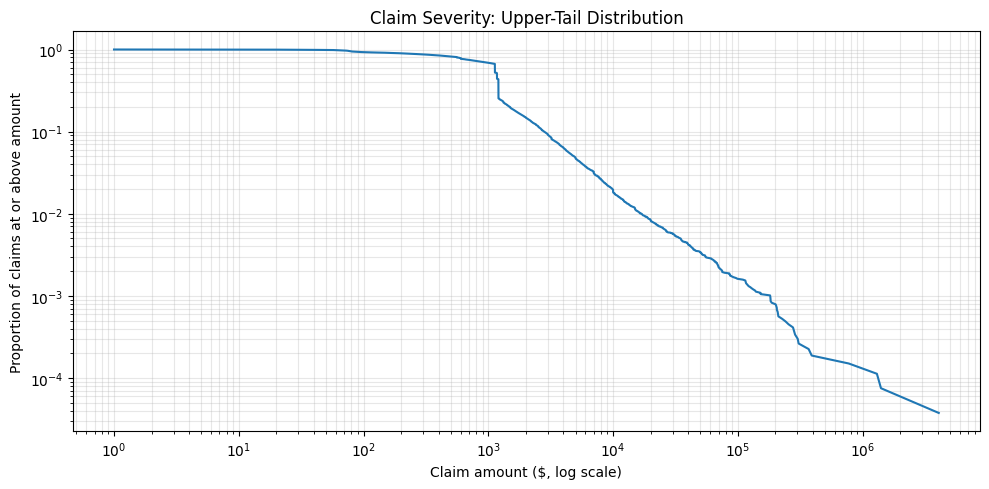

In [34]:
import numpy as np
import matplotlib.pyplot as plt

claims_sorted = np.sort(sev["ClaimAmount"].to_numpy())
n = len(claims_sorted)

# Proportion of claims greater than or equal to each amount
survival_prob = (n - np.arange(n)) / n

plt.figure(figsize=(10, 5))
plt.plot(claims_sorted, survival_prob)
plt.xscale("log")
plt.yscale("log")
plt.title("Claim Severity: Upper-Tail Distribution")
plt.xlabel("Claim amount ($, log scale)")
plt.ylabel("Proportion of claims at or above amount")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Identify the most frequently occurring claim amounts
claim_amount_counts = (
    sev["ClaimAmount"]
    .value_counts()
    .rename_axis("ClaimAmount")
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

claim_amount_counts.head(10)

,ClaimAmount,Count
0,1204.00,4792
1,1128.12,3056
2,1172.00,2072
3,1128.00,831
4,602.00,433
5,1320.00,175
6,556.14,155
7,586.00,104
8,1500.00,103
9,564.06,94


In [36]:
# Examine the three most frequent exact claim amounts
top_amounts = sev["ClaimAmount"].value_counts().head(3).index

top_amount_summary = (
    sev[sev["ClaimAmount"].isin(top_amounts)]
    .groupby("ClaimAmount")
    .agg(
        ClaimCount=("ClaimAmount", "size"),
        TotalClaimCost=("ClaimAmount", "sum")
    )
    .reset_index()
)

top_amount_summary["ShareOfClaims (%)"] = (
    100 * top_amount_summary["ClaimCount"] / len(sev)
)

top_amount_summary["ShareOfTotalCost (%)"] = (
    100 * top_amount_summary["TotalClaimCost"] / sev["ClaimAmount"].sum()
)

top_amount_summary.round(2)

,ClaimAmount,ClaimCount,TotalClaimCost,ShareOfClaims (%),ShareOfTotalCost (%)
0,1128.12,3056,3447534.72,11.47,5.68
1,1172.00,2072,2428384.00,7.78,4.00
2,1204.00,4792,5769568.00,17.99,9.51


In [37]:
import numpy as np
import pandas as pd
from scipy.stats import gamma, lognorm

claims = sev["ClaimAmount"].to_numpy()

# Fit both distributions, fixing location at zero
gamma_params = gamma.fit(claims, floc=0)
lognorm_params = lognorm.fit(claims, floc=0)

# Calculate log-likelihood on the original claim-amount scale
gamma_loglik = np.sum(gamma.logpdf(claims, *gamma_params))
lognorm_loglik = np.sum(lognorm.logpdf(claims, *lognorm_params))

# Each model estimates two free parameters when loc is fixed at zero
k = 2

comparison = pd.DataFrame({
    "Distribution": ["Gamma", "Lognormal"],
    "Log-Likelihood": [gamma_loglik, lognorm_loglik],
    "AIC": [
        2 * k - 2 * gamma_loglik,
        2 * k - 2 * lognorm_loglik
    ]
})

comparison.round(2)

,Distribution,Log-Likelihood,AIC
0,Gamma,-231154.01,462312.01
1,Lognormal,-223590.14,447184.27


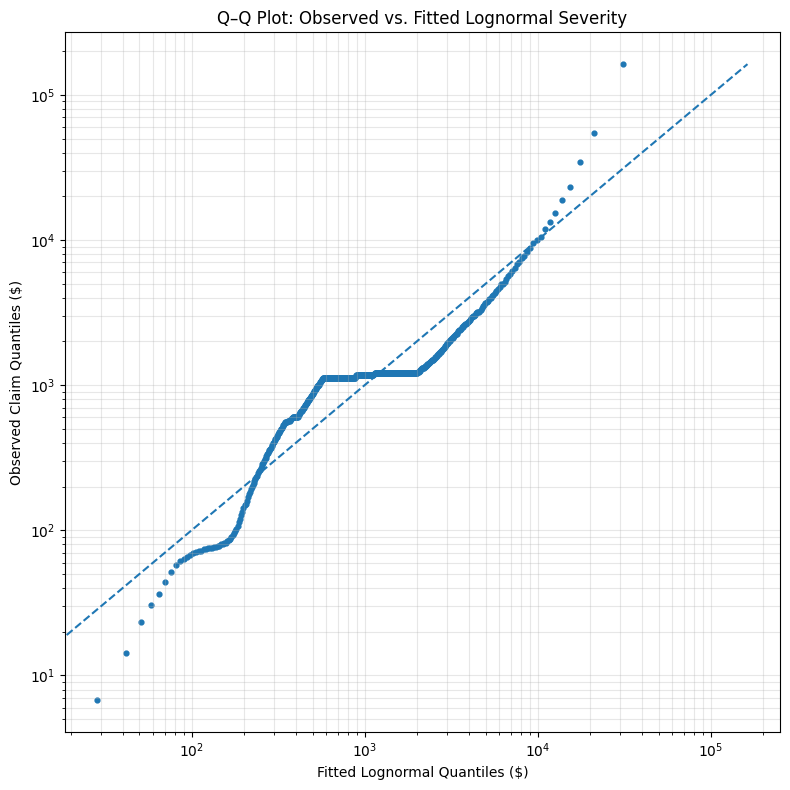

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm

claims = sev["ClaimAmount"].to_numpy()

# Fit the lognormal distribution, fixing location at zero
shape, loc, scale = lognorm.fit(claims, floc=0)

# Calculate matching theoretical and observed quantiles
probabilities = np.linspace(0.001, 0.999, 500)

observed_quantiles = np.quantile(claims, probabilities)
fitted_quantiles = lognorm.ppf(
    probabilities, shape, loc=loc, scale=scale
)

plt.figure(figsize=(8, 8))
plt.scatter(fitted_quantiles, observed_quantiles, s=12)

# Reference line: perfect agreement
upper = max(observed_quantiles.max(), fitted_quantiles.max())
plt.plot([0, upper], [0, upper], linestyle="--")

plt.xscale("log")
plt.yscale("log")
plt.title("Q–Q Plot: Observed vs. Fitted Lognormal Severity")
plt.xlabel("Fitted Lognormal Quantiles ($)")
plt.ylabel("Observed Claim Quantiles ($)")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Attach driver age group to each policy in the frequency data
policy_ages = model_data[["IDpol", "DriverAgeGroup"]].drop_duplicates()

# Match each individual claim to its policy's driver age group
severity_by_age = sev.merge(
    policy_ages,
    on="IDpol",
    how="inner"
)

# Calculate frequency by driver age group
frequency_by_age = (
    model_data.groupby("DriverAgeGroup", observed=True)
    .agg(
        Policies=("IDpol", "size"),
        TotalClaims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

frequency_by_age["ClaimsPer100PolicyYears"] = (
    100 * frequency_by_age["TotalClaims"]
    / frequency_by_age["Exposure"]
)

# Calculate average severity by driver age group
severity_summary = (
    severity_by_age.groupby("DriverAgeGroup", observed=True)
    .agg(
        MatchedClaimCount=("ClaimAmount", "size"),
        TotalClaimCost=("ClaimAmount", "sum"),
        AverageSeverity=("ClaimAmount", "mean")
    )
)

# Combine frequency and severity estimates
pure_premium = frequency_by_age.join(severity_summary)

pure_premium["PurePremium"] = (
    pure_premium["TotalClaims"]
    / pure_premium["Exposure"]
    * pure_premium["AverageSeverity"]
)

pure_premium[
    [
        "Policies",
        "ClaimsPer100PolicyYears",
        "MatchedClaimCount",
        "AverageSeverity",
        "PurePremium"
    ]
].round(2)

,Policies,ClaimsPer100PolicyYears,MatchedClaimCount,AverageSeverity,PurePremium
DriverAgeGroup,,,,,
18-24,30198,18.93,2011,5838.56,1105.15
25-34,140947,9.90,4973,2002.30,198.25
35-44,170578,9.32,6192,1983.93,184.90
45-54,164034,10.59,6802,1847.96,195.65
55-64,99094,9.12,3602,1859.34,169.59
65+,73162,9.50,2864,2325.00,220.92


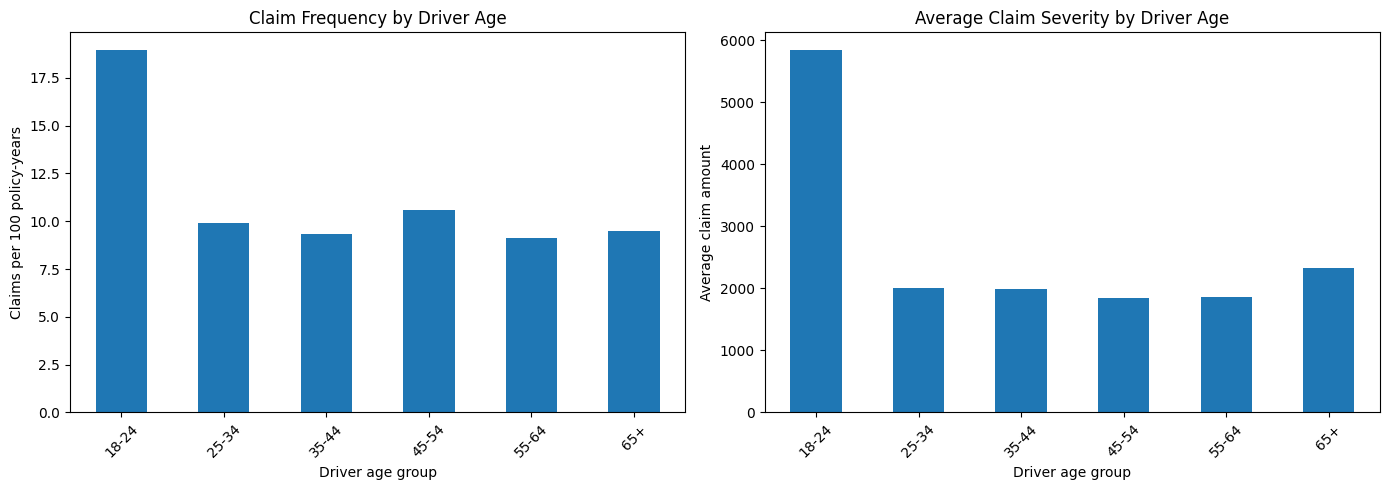

In [40]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pure_premium["ClaimsPer100PolicyYears"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Claim Frequency by Driver Age")
axes[0].set_ylabel("Claims per 100 policy-years")
axes[0].set_xlabel("Driver age group")
axes[0].tick_params(axis="x", rotation=45)

pure_premium["AverageSeverity"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Average Claim Severity by Driver Age")
axes[1].set_ylabel("Average claim amount")
axes[1].set_xlabel("Driver age group")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()